<a href="https://colab.research.google.com/github/wendymarquez257/M-todos-Num-ricos-I/blob/main/Diferencias%20Divididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Análisis Numérico: Fórmula de las Diferencias Divididas de Newton
**Algoritmo 3.2 (Página 93) y Ejemplo 1 (Página 94) — Burden & Faires**

- **Alumna:** Wendy Aidee Márquez Muñoz
- **Institución:** Instituto Politécnico Nacional (IPN)
- **Escuela:** Escuela Superior de Física y Matemáticas (ESFM)

---

##Formulación del Problema y Método de Diferencias Divididas

La **fórmula de las diferencias divididas de Newton** permite construir el polinomio interpolante $P_n(x)$ a partir de $n + 1$ nodos distintos $x_0, x_1, \dots, x_n$ y sus valores $f(x_0), f(x_1), \dots, f(x_n)$[cite: 3]. Los coeficientes de la forma de diferencias divididas hacia adelante corresponden a las entradas diagonales $F_{0,0}, F_{1,1}, \dots, F_{n,n}$[cite: 3, 4].

El algoritmo se estructura mediante las siguientes relaciones:

1. **Inicialización:** Se asignan los valores $F_{i,0} = f(x_i)$ para $i = 0, 1, \dots, n$[cite: 3].

2. **Cálculo de diferencias divididas:** Para $i = 1, 2, \dots, n$ y $j = 1, 2, \dots, i$:
   $$F_{i,j} = \frac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}$$
   donde $F_{i,j} = f[x_{i-j}, \dots, x_i]$[cite: 3].

3. **Polinomio de interpolación de Newton:** Utilizando los coeficientes diagonales $F_{i,i} = f[x_0, x_1, \dots, x_i]$[cite: 3]:
   $$P_n(x) = F_{0,0} + \sum_{i=1}^{n} F_{i,i} \prod_{j=0}^{i-1} (x - x_j)$$

###Ejemplo 1 (Página 94)
A partir de los datos de la **Tabla 3.10** ($n = 4$), se completa la tabla de diferencias divididas (**Tabla 3.11**) y se construye el polinomio de interpolación $P_4(x)$:

| $i$ | $x_i$ | $f(x_i) = F_{i,0}$ |
| :---: | :---: | :---: |
| $0$ | $1.0$ | $0.7651977$ |
| $1$ | $1.3$ | $0.6200860$ |
| $2$ | $1.6$ | $0.4554022$ |
| $3$ | $1.9$ | $0.2818186$ |
| $4$ | $2.2$ | $0.1103623$ |

---

In [38]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

In [39]:
def diferencias_divididas_newton(nodos_x, valores_y):

    m=len(nodos_x)
    F=np.zeros((m, m), dtype=float)

    F[:, 0]=valores_y

    for i in range(1, m):
        for j in range(1, i+1):
            F[i, j]=(F[i, j-1]-F[i-1, j-1])/(nodos_x[i]-nodos_x[i-j])

    coeficientes=np.diag(F)
    return F, coeficientes

In [40]:
def construir_polinomio_newton(nodos_x, coeficientes):

    x=sp.Symbol('x')
    polinomio_newton=coeficientes[0]
    termino_producto=1

    for i in range(1, len(coeficientes)):
        termino_producto*=(x-nodos_x[i-1])
        polinomio_newton+=coeficientes[i]*termino_producto

    polinomio_expandido=sp.expand(polinomio_newton)

    print("Polinomio de Newton (forma de diferencias divididas):")
    sp.pprint(polinomio_newton)

    print("\nPolinomio expandido:")
    sp.pprint(polinomio_expandido)

    return x, polinomio_newton, polinomio_expandido

In [41]:
def graficar_polinomio_newton(x_sym, polinomio_expr, nodos_x, valores_y):

    f_num=sp.lambdify(x_sym, polinomio_expr, 'numpy')
    x_vals=np.linspace(min(nodos_x), max(nodos_x), 200)
    y_vals=f_num(x_vals)

    plt.figure(figsize=(8, 4.5))
    plt.plot(x_vals, y_vals, color='#1B365D', linewidth=2, label='Polinomio de Newton $P_4(x)$')
    plt.scatter(nodos_x, valores_y, color='#C0392B', s=65, zorder=5, label='Nodos dados (Tabla 3.10)')

    plt.title('Polinomio Interpolante de Newton — Ejemplo 1 (Burden)', fontweight='bold')
    plt.xlabel('$x$')
    plt.ylabel('$P_4(x)$')
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend()
    plt.tight_layout()
    plt.show()

Coeficientes diagonales (F_{0,0} a F_{4,4}):
F_0,0 = 0.7651977
F_1,1 = -0.4837057
F_2,2 = -0.1087339
F_3,3 = 0.0658784
F_4,4 = 0.0018251

-----------------------------------------------------------------
Polinomio de Newton (forma de diferencias divididas):
-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667

Polinomio expandido:
                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪

↪                                   
↪ 913477366034⋅x + 0.977735055967085


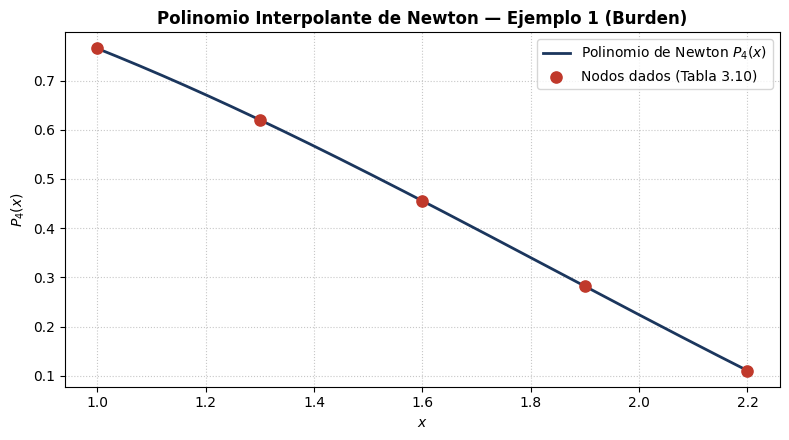

In [42]:
x_datos=[1.0, 1.3, 1.6, 1.9, 2.2]
y_datos=[0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

matriz_F, coef_diag = diferencias_divididas_newton(x_datos, y_datos)

print("Coeficientes diagonales (F_{0,0} a F_{4,4}):")
for idx, c in enumerate(coef_diag):
    print(f"F_{idx},{idx} = {c:.7f}")

print("\n"+"-"*65)
x_sym, pol_newton, pol_exp = construir_polinomio_newton(x_datos, coef_diag)
print("="*65)

graficar_polinomio_newton(x_sym, pol_newton, x_datos, y_datos)

---
##Conclusión

Los coeficientes diagonales obtenidos coinciden con la **Tabla 3.11** del Ejemplo 1:

- $F_{0,0} = 0.7651977$
- $F_{1,1} = -0.4837057$
- $F_{2,2} = -0.1087339$
- $F_{3,3} = 0.0658784$
- $F_{4,4} = 0.0018251$

> **Solución Final:**
> El polinomio de interpolación en forma de diferencias divididas hacia adelante de Newton es:
> $$P_4(x) = 0.7651977 - 0.4837057(x - 1.0) - 0.1087339(x - 1.0)(x - 1.3) + 0.0658784(x - 1.0)(x - 1.3)(x - 1.6) + 0.0018251(x - 1.0)(x - 1.3)(x - 1.6)(x - 1.9)$$